# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [12]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    select_existing_columns,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)


## Configuration


In [14]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PARQUET_OUTPUT_DIR = OUTPUT_DIR / "parquets"
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = PARQUET_OUTPUT_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PARQUET_OUTPUT_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = PROJECT_ROOT / "assets" / "antibiotic_coarsening_lookup.csv"
DRIVER_CATEGORY_COARSENING_PATH = PROJECT_ROOT / "assets" / "amr_driver_category_coarsening.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "antibiotic"  # antibiotic, Class, Simplified categories, High level categories, Origin
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]

FIT_START_YEAR = 2000  # First year included when fitting historical SI/count trends.
FIT_END_YEAR = 2023  # Last observed year used for model fitting; later years are treated as holdout/future checks.
NUM_FUTURE_YEARS = 5  # Number of years projected beyond FIT_END_YEAR for future SI/count forecasts.

MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = 4.0  # Minimum mean AMR publication count per pathogen-antibiotic pair across the fit window.
MIN_CURRENT_PREDICTED_COUNT = 10  # Minimum predicted publication count at FIT_END_YEAR required for ranking a pair.
MIN_FUTURE_PREDICTED_COUNT = 10  # Minimum predicted publication count in the projected future year required for ranking a pair.
MIN_SI_CHANGE = 0.01  # Minimum projected SI increase needed for a pair to be considered interesting.
MIN_POST_FIT_OBSERVED_YEARS = 1  # Minimum observed years after FIT_END_YEAR required to estimate forecast error.
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 100.0  # Maximum allowed mean absolute percent error for post-fit SI forecasts.
FALLBACK_TOP_N = 10  # Number of top-ranked pairs retained if strict interesting-pair filters return too few rows.

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")  # LLM inclusion decisions counted in category-driver summaries.
DRIVER_CATEGORY_LEVEL = "coarse"  # Category plot level: "original" for fine LLM categories, or "coarse" for grouped concepts.
DRIVER_LOOKBACK_YEARS = 5  # Number of years before FIT_END_YEAR used to summarize recent driver-category changes.
MAX_DRIVER_PLOTS = 25  # Maximum number of category-driver plots to save.
MAX_INTERESTING_PLOTS = 25  # Maximum number of SI forecast plots to save for interesting pairs.
FIGURE_FORMAT = "pdf"  # File extension/format used when saving figures.
DISPLAY_PLOTS = True  # Whether to display saved figures inline in the notebook.
MAX_DISPLAY_PLOTS = 10  # Maximum number of saved figures displayed inline per plotting section.
FILL_MISSING_AMR_COUNTS_WITH_ZERO = True  # Treat missing pair-year AMR counts as zero when fitting and plotting time series.
PLOT_END_YEAR = FIT_END_YEAR + NUM_FUTURE_YEARS  # Final year shown on plots, including the projection horizon.


## Load Canonical Inputs


In [15]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 22,872
yearly_screened unique pathogens: 48
yearly_screened unique antibiotics: 197
yearly_screened year range: 2000 - 2026
pathogen bg rows: 1,296
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 161,140


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 22,872
model pathogen-antibiotic rows: 2,903
model antibiotic values: 197
model antibiotic background rows: 5,319
model unified decision rows: 161,140


,pathogen,antibiotic,year,pmids,count
0,Acinetobacter baumannii,Amikacin,2001,"[11192508, 11450883, 12593705]",3
1,Acinetobacter baumannii,Amikacin,2002,"[11864948, 12481673]",2
2,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14619453, 14748260]",3
3,Acinetobacter baumannii,Amikacin,2004,"[14964402, 15004037, 15164966, 15221039, 16163...",5
4,Acinetobacter baumannii,Amikacin,2005,"[15667800, 16103700, 16258323, 16308938]",4
5,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2
6,Acinetobacter baumannii,Amikacin,2007,"[17762241, 18167265]",2
7,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18624668, 18792817, 18974485, 19037...",6
8,Acinetobacter baumannii,Amikacin,2009,"[19795613, 19949755, 20583564]",3
9,Acinetobacter baumannii,Amikacin,2010,"[20028819, 20107089, 20194701, 20499531, 20587...",9


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [6]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 241 / 2,903 pairs with >= 4 publications/year on average from 2000 to 2023.
model input before publication filter pathogens: 48
model input after publication filter pathogens: 19
Pathogens present in model input before publication filter but absent from model input after publication filter: 29
Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cepacia, Burkholderia pseudomallei, Chlamydia pneumoniae, Chlamydia trachomatis, Clostridium perfringens, Coxiella burnetii, Cutibacterium acnes, Francisella tularensis, Legionella pneumophila, Moraxella catarrhalis, Mycobacterium abscessus, Mycobacterium avium, Mycobacterium leprae, Mycoplasmoides pneumoniae, Neisseria meningitidis, Orientia tsutsugamushi, Porphyromonas gingivalis, Shigella flexneri, Stenotrophomonas maltophilia, Treponema pallidum, Vibrio cholerae, Vibrio parahaemolyticus, Yersinia enterocolitica, Yersinia pestis


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Aggregatibacter actinomycetemcomitans,97,114,21,0.0,0.0,0.0,True,False,missing_from_modeled
1,Bacillus anthracis,78,62,47,0.0,0.0,0.0,True,False,missing_from_modeled
2,Bordetella pertussis,71,97,25,0.0,0.0,0.0,True,False,missing_from_modeled
3,Borrelia burgdorferi,41,43,23,0.0,0.0,0.0,True,False,missing_from_modeled
4,Brucella melitensis,124,170,31,0.0,0.0,0.0,True,False,missing_from_modeled
5,Burkholderia cepacia,262,403,48,0.0,0.0,0.0,True,False,missing_from_modeled
6,Burkholderia pseudomallei,163,227,47,0.0,0.0,0.0,True,False,missing_from_modeled
7,Chlamydia pneumoniae,45,47,21,0.0,0.0,0.0,True,False,missing_from_modeled
8,Chlamydia trachomatis,150,154,38,0.0,0.0,0.0,True,False,missing_from_modeled
9,Clostridium perfringens,265,412,67,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
2038,Staphylococcus aureus,Meticillin,4818,200.750000
804,Escherichia coli,Ampicillin,2101,87.541667
853,Escherichia coli,Ciprofloxacin,1799,74.958333
955,Escherichia coli,Tetracycline,1646,68.583333
2098,Staphylococcus aureus,Vancomycin,1577,65.708333
961,Escherichia coli,Trimethoprim,1460,60.833333
944,Escherichia coli,Sulfamethoxazole,1202,50.083333
945,Escherichia coli,Sulfamethoxazole/trimethoprim,1081,45.041667
1081,Helicobacter pylori,Clarithromycin,1047,43.625000
884,Escherichia coli,Gentamicin,1000,41.666667


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [7]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 6,209
SI pairs: 241
SI pathogens: 19
filtered model input pathogens: 19
yearly SI output pathogens: 19


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Acinetobacter baumannii,Amikacin,2001,"[11192508, 11450883, 12593705]",3,60,167,0.602060,1.785330,2.225309,0.163518,0.457195,0.438542
1,Acinetobacter baumannii,Amikacin,2002,"[11864948, 12481673]",2,80,156,0.477121,1.908485,2.195900,0.233654,0.712592,0.243467
2,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14619453, 14748260]",3,80,183,0.602060,1.908485,2.264818,0.273875,0.878774,0.328185
3,Acinetobacter baumannii,Amikacin,2004,"[14964402, 15004037, 15164966, 15221039, 16163...",5,93,180,0.778151,1.973128,2.257679,0.315531,1.067906,0.462620
4,Acinetobacter baumannii,Amikacin,2005,"[15667800, 16103700, 16258323, 16308938]",4,139,187,0.698970,2.146128,2.274158,0.447781,1.804020,0.251189
5,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2,176,194,0.477121,2.247973,2.290035,0.529241,2.382523,-0.052119
6,Acinetobacter baumannii,Amikacin,2007,"[17762241, 18167265]",2,205,192,0.477121,2.313867,2.285557,0.573337,2.744013,-0.096216
7,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18624668, 18792817, 18974485, 19037...",6,247,228,0.845098,2.394452,2.359835,0.673809,3.718557,0.171289
8,Acinetobacter baumannii,Amikacin,2009,"[19795613, 19949755, 20583564]",3,287,256,0.602060,2.459392,2.409933,0.749080,4.611515,-0.147020
9,Acinetobacter baumannii,Amikacin,2010,"[20028819, 20107089, 20194701, 20499531, 20587...",9,342,265,1.000000,2.535294,2.424882,0.811608,5.480488,0.188392


## Rank Reliable Future High-Interest Pairs


In [8]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/241] ranking Acinetobacter baumannii vs Amikacin
[2/241] ranking Acinetobacter baumannii vs Ampicillin
[3/241] ranking Acinetobacter baumannii vs Cefepime
[4/241] ranking Acinetobacter baumannii vs Ceftazidime
[5/241] ranking Acinetobacter baumannii vs Ceftolozane/tazobactam
[6/241] ranking Acinetobacter baumannii vs Ciprofloxacin
[7/241] ranking Acinetobacter baumannii vs Colistin
[8/241] ranking Acinetobacter baumannii vs Gentamicin
[9/241] ranking Acinetobacter baumannii vs Levofloxacin
[10/241] ranking Acinetobacter baumannii vs Meropenem
[11/241] ranking Acinetobacter baumannii vs Meticillin
[12/241] ranking Acinetobacter baumannii vs Piperacillin
[13/241] ranking Acinetobacter baumannii vs Piperacillin/tazobactam
[14/241] ranking Acinetobacter baumannii vs Sulbactam
[15/241] ranking Acinetobacter baumannii vs Tazobactam
[16/241] ranking Acinetobacter baumannii vs Tetracycline
[17/241] ranking Acinetobacter baumannii vs Tigecycline
[18/241] ranking Acinetobacter baumannii vs Tr

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Escherichia coli,Colistin,0.216219,0.452811,232.762468,917.158947,70.053053
1,Klebsiella pneumoniae,Ceftazidime/avibactam,0.187236,0.353062,38.177862,160.309880,25.800352
2,Escherichia coli,Meropenem,0.177747,0.283900,104.567654,306.238310,15.536354
3,Escherichia coli,Fosfomycin,0.137443,0.234310,55.843039,135.519491,15.286550
4,Escherichia coli,Vancomycin,0.136541,0.302753,24.590092,62.571817,44.163218
5,Pseudomonas aeruginosa,Meticillin,0.132846,0.235356,49.439990,119.341187,19.867306
6,Escherichia coli,Cefotaxime,0.126617,0.211114,114.652850,243.319694,24.954555
7,Klebsiella pneumoniae,Colistin,0.118984,0.195356,107.730139,292.296037,21.102171
8,Escherichia coli,Erythromycin,0.118074,0.219201,38.994705,76.226078,23.484414
9,Escherichia coli,Doxycycline,0.117830,0.224686,21.355117,46.830761,15.756643


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [9]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Escherichia coli,Colistin,0.216219,0.452811,232.762468,917.158947,684,518,RESISTANCE_PREVALENCE_SURVEILLANCE,ONE_HEALTH_ENVIRONMENTAL_RESERVOIR,0.005848,0.916667
1,Klebsiella pneumoniae,Ceftazidime/avibactam,0.187236,0.353062,38.177862,160.309880,110,93,RESISTANCE_MECHANISM,RESISTANCE_MECHANISM,0.009091,0.881818
2,Escherichia coli,Meropenem,0.177747,0.283900,104.567654,306.238310,372,260,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_MECHANISM,0.002688,0.844086
3,Escherichia coli,Fosfomycin,0.137443,0.234310,55.843039,135.519491,208,136,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.764423
4,Escherichia coli,Vancomycin,0.136541,0.302753,24.590092,62.571817,90,57,RESISTANCE_PREVALENCE_SURVEILLANCE,TREATMENT_EFFECTIVENESS,0.000000,0.877778
5,Pseudomonas aeruginosa,Meticillin,0.132846,0.235356,49.439990,119.341187,184,114,RESISTANCE_PREVALENCE_SURVEILLANCE,TREATMENT_REUSE_OR_SALVAGE,0.000000,0.918478
6,Escherichia coli,Cefotaxime,0.126617,0.211114,114.652850,243.319694,439,239,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.879271
7,Klebsiella pneumoniae,Colistin,0.118984,0.195356,107.730139,292.296037,376,266,RESISTANCE_PREVALENCE_SURVEILLANCE,ONE_HEALTH_ENVIRONMENTAL_RESERVOIR,0.005319,0.901596
8,Escherichia coli,Erythromycin,0.118074,0.219201,38.994705,76.226078,152,75,RESISTANCE_PREVALENCE_SURVEILLANCE,TREATMENT_EFFECTIVENESS,0.000000,0.868421
9,Escherichia coli,Doxycycline,0.117830,0.224686,21.355117,46.830761,82,48,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_MECHANISM,0.000000,0.853659


## Plot Category Driver Curves


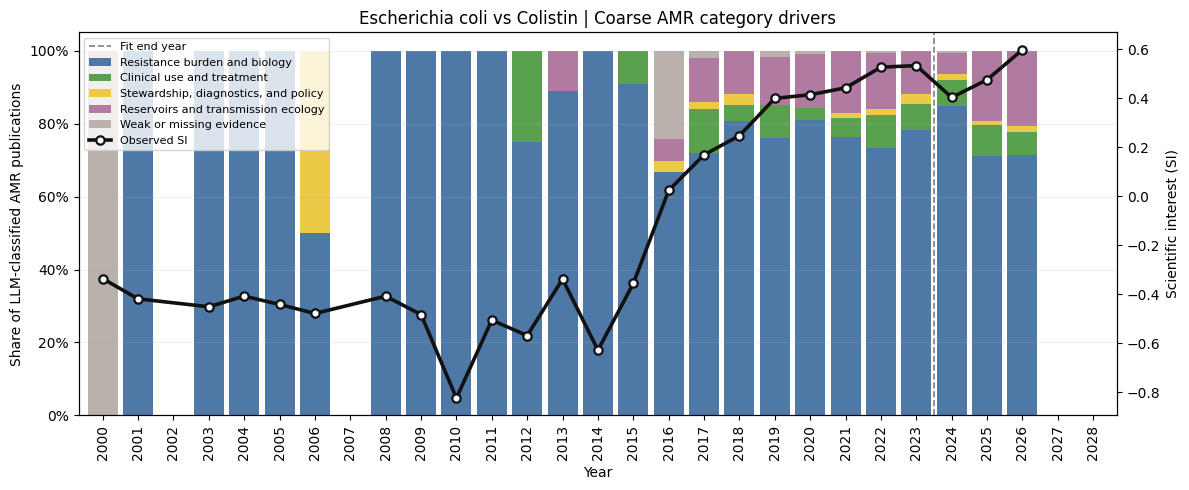

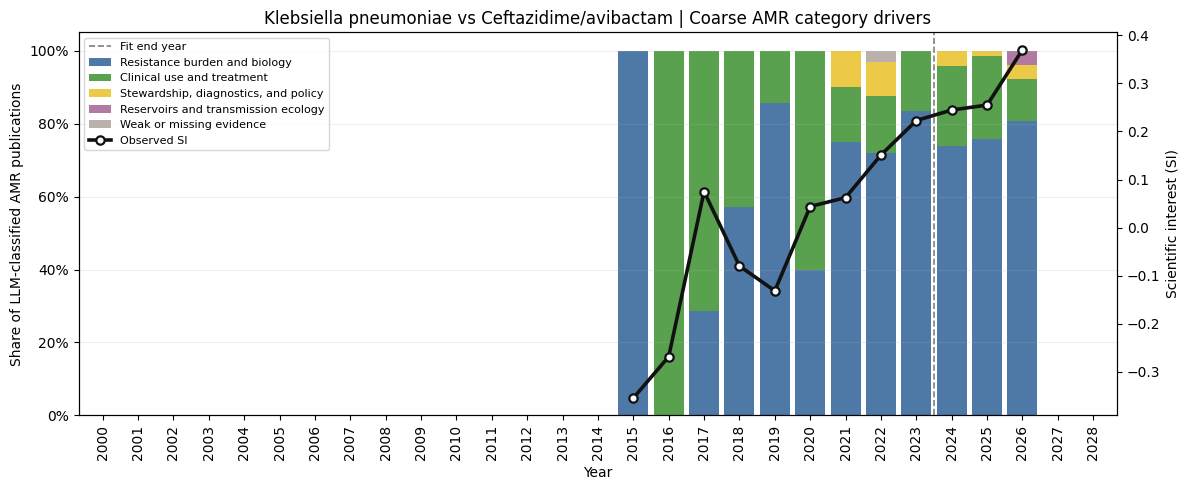

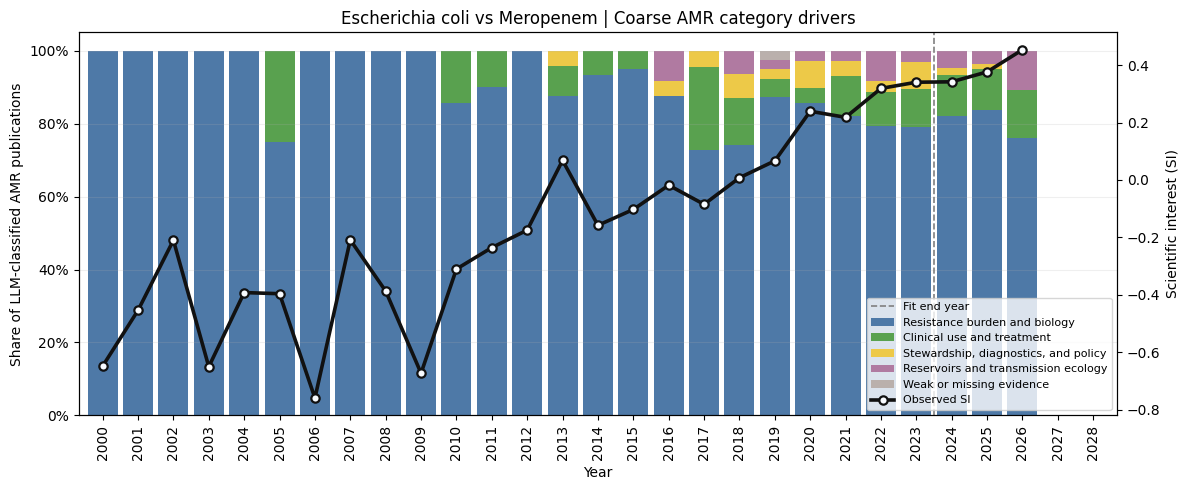

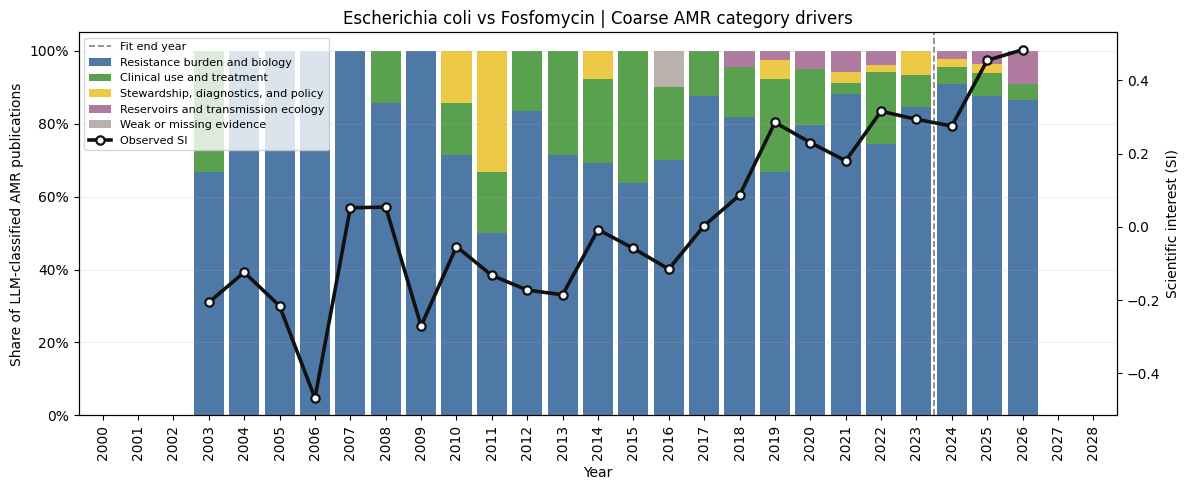

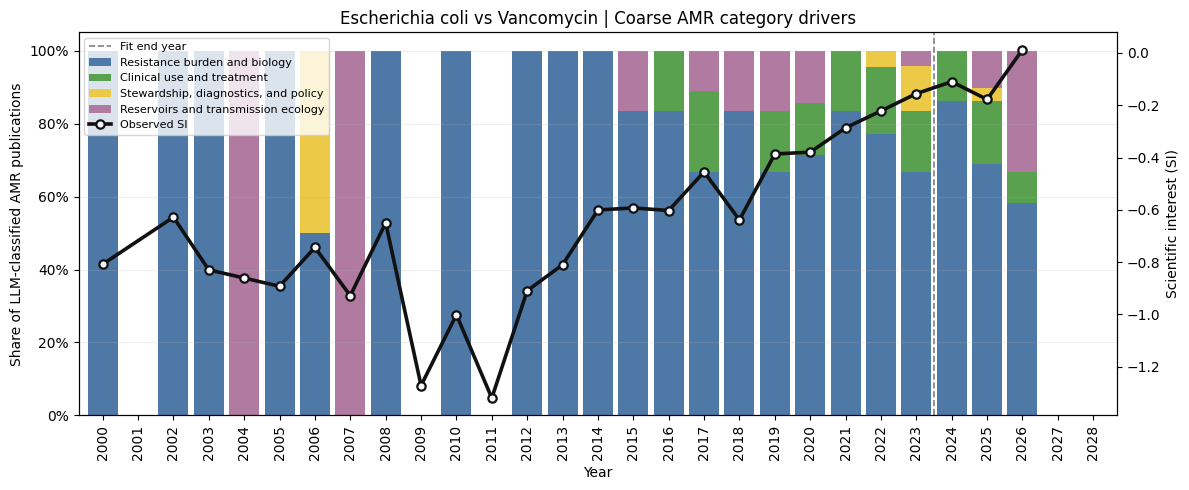

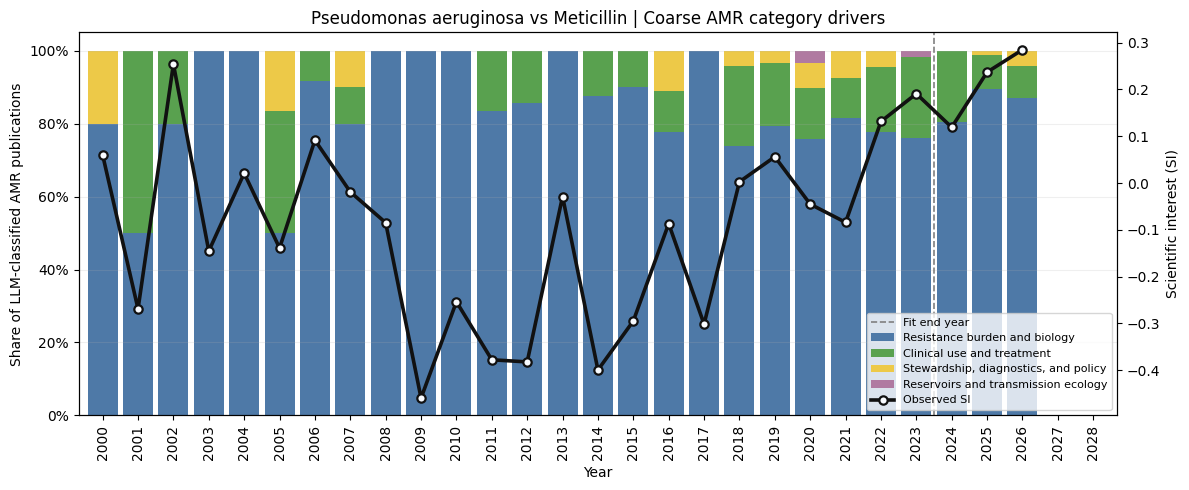

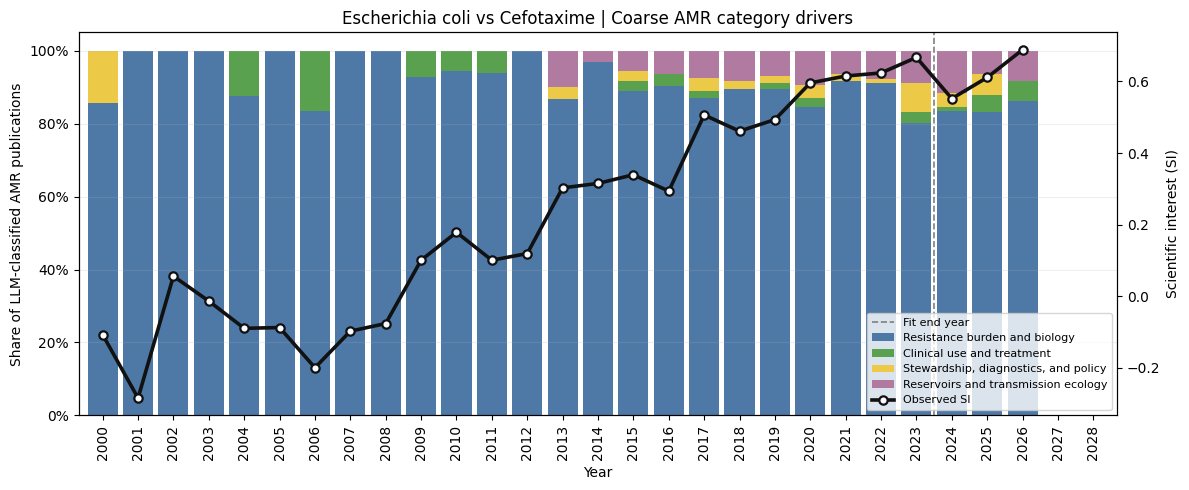

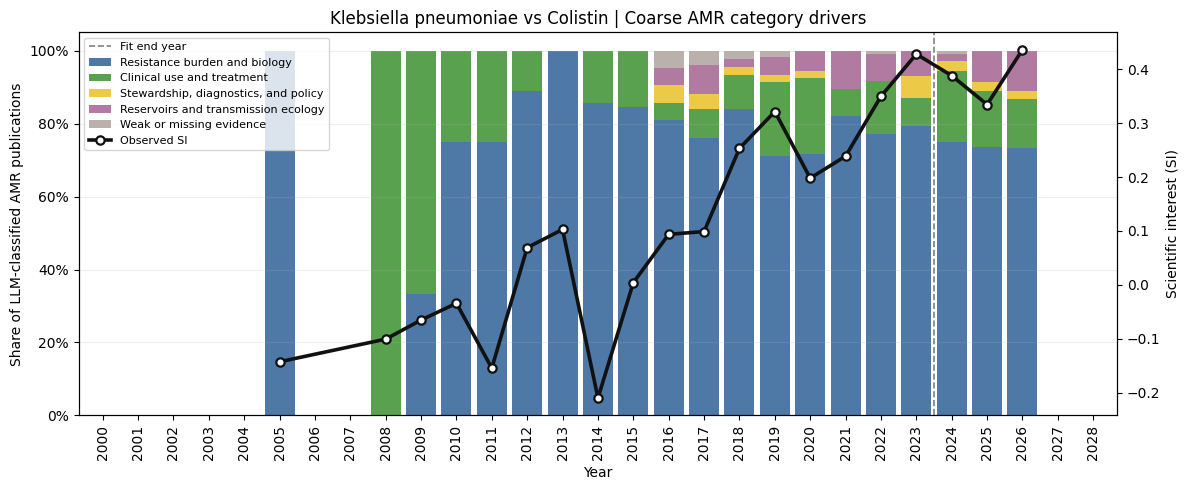

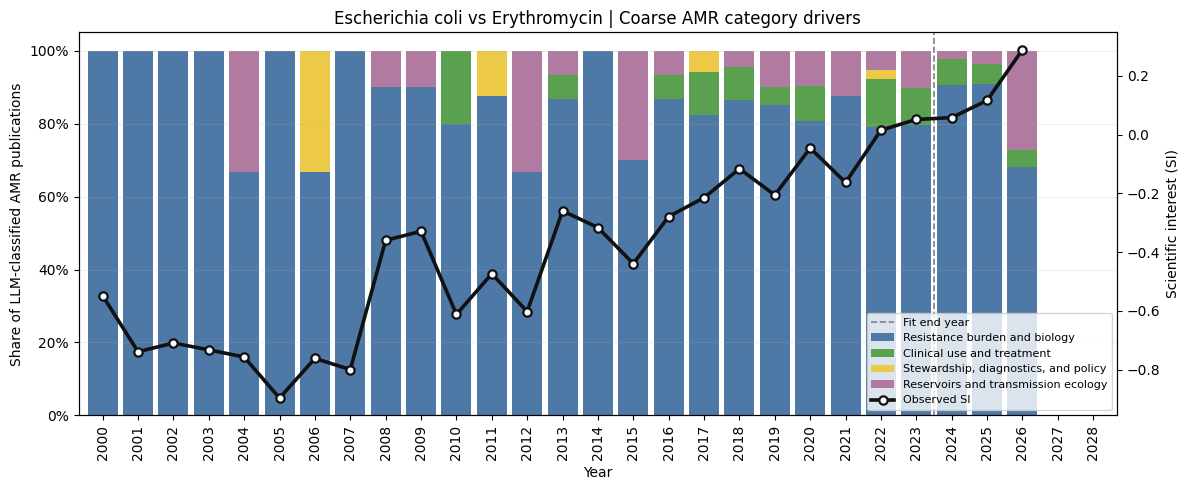

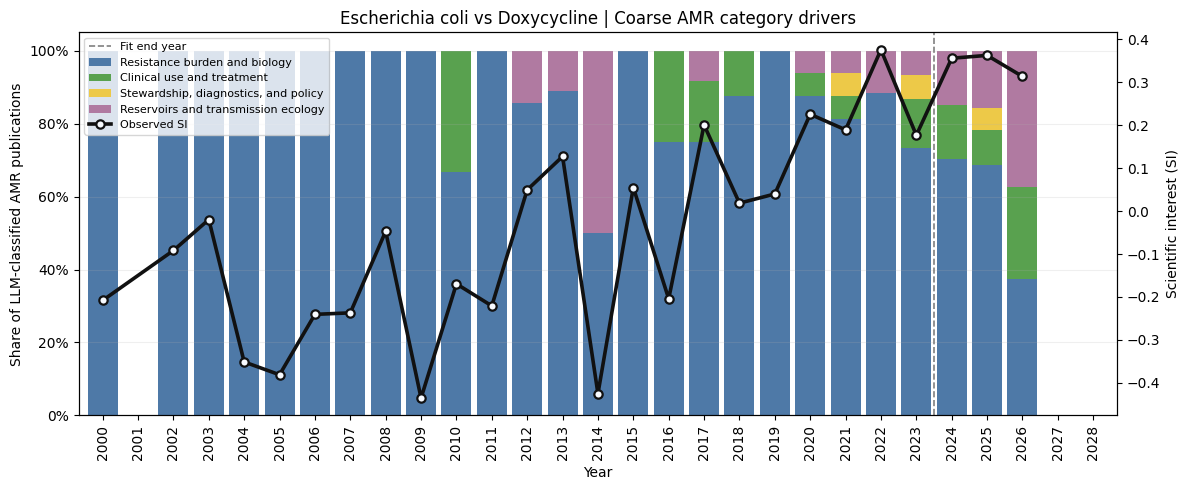

Saved 25 coarse category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.


In [10]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


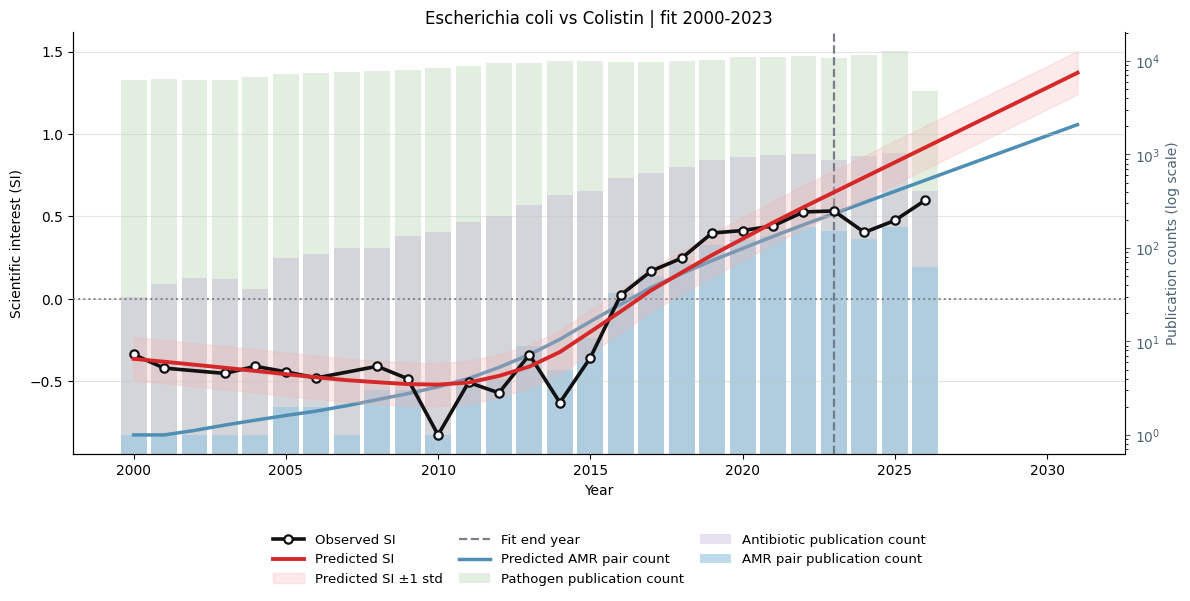

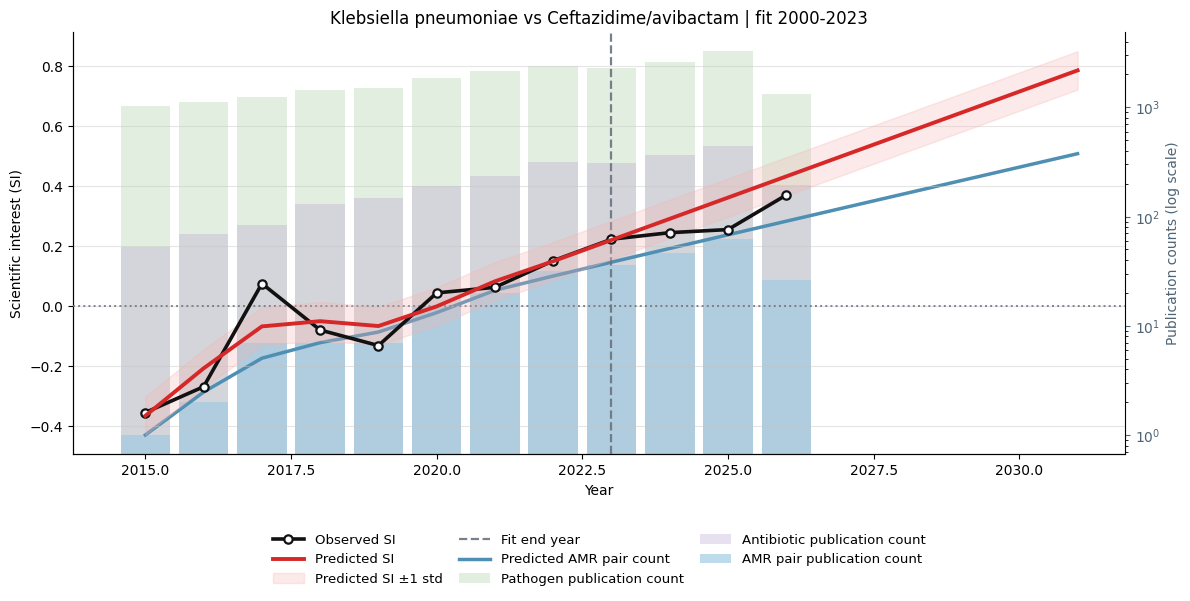

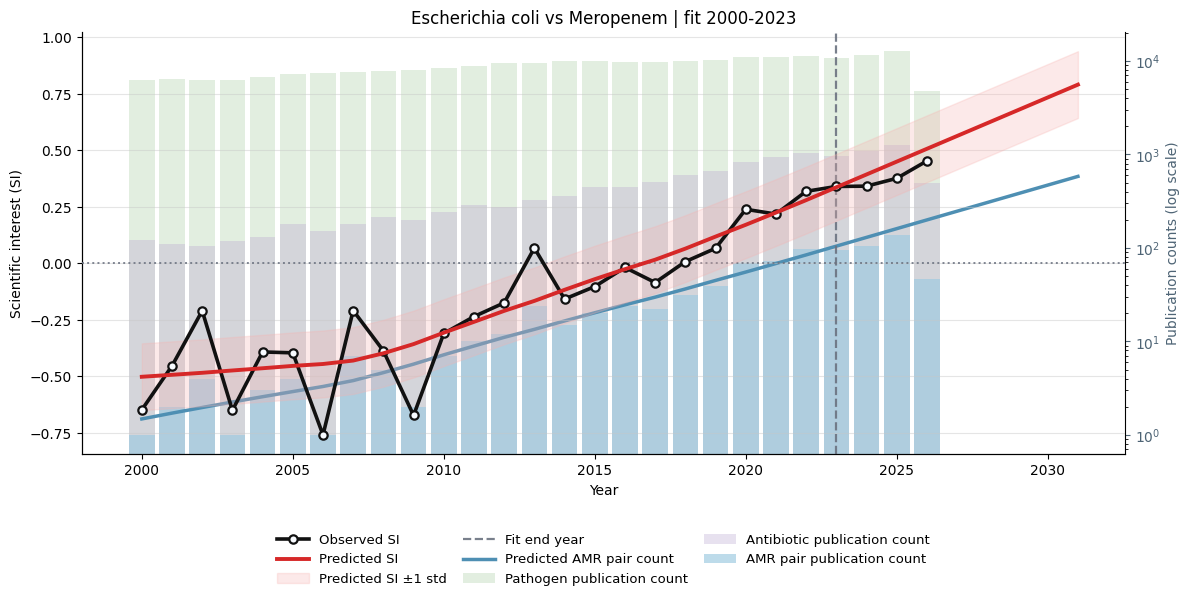

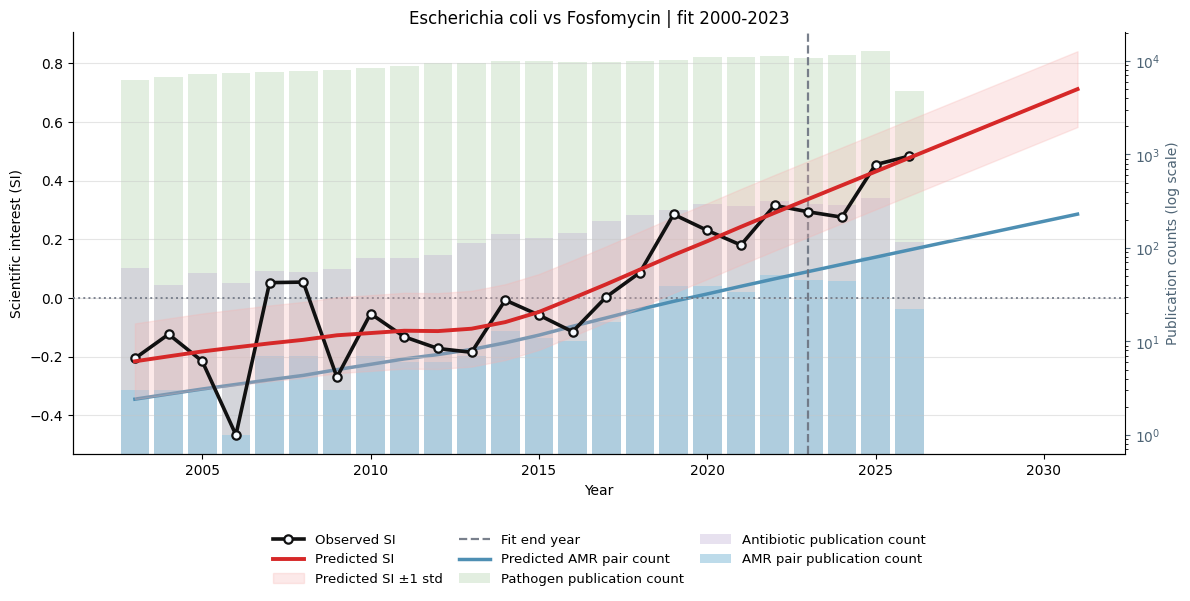

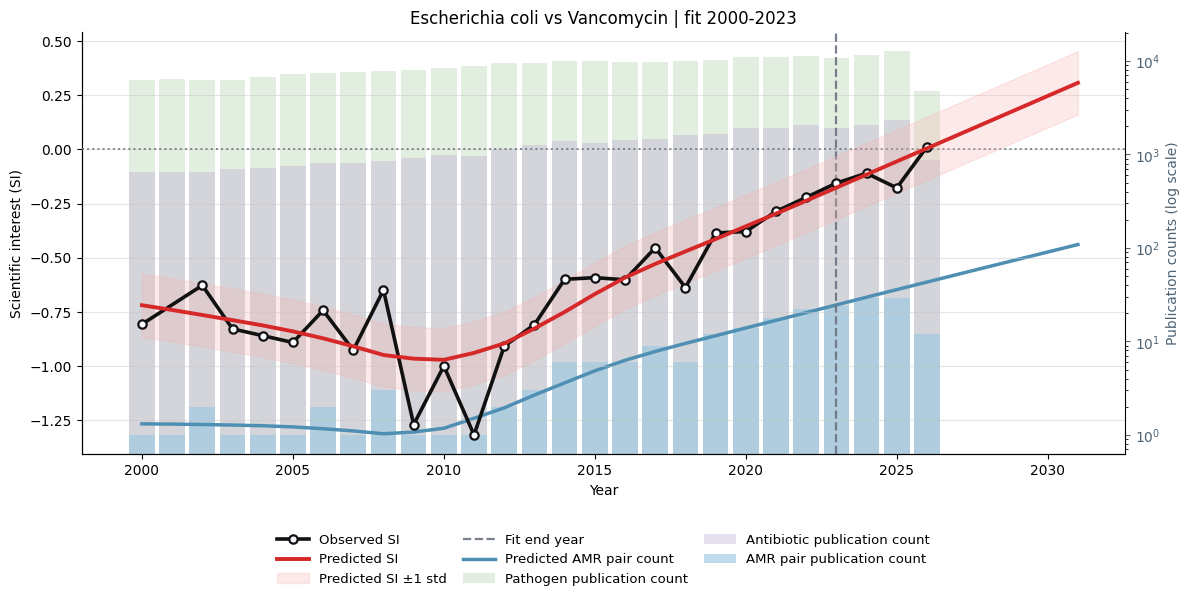

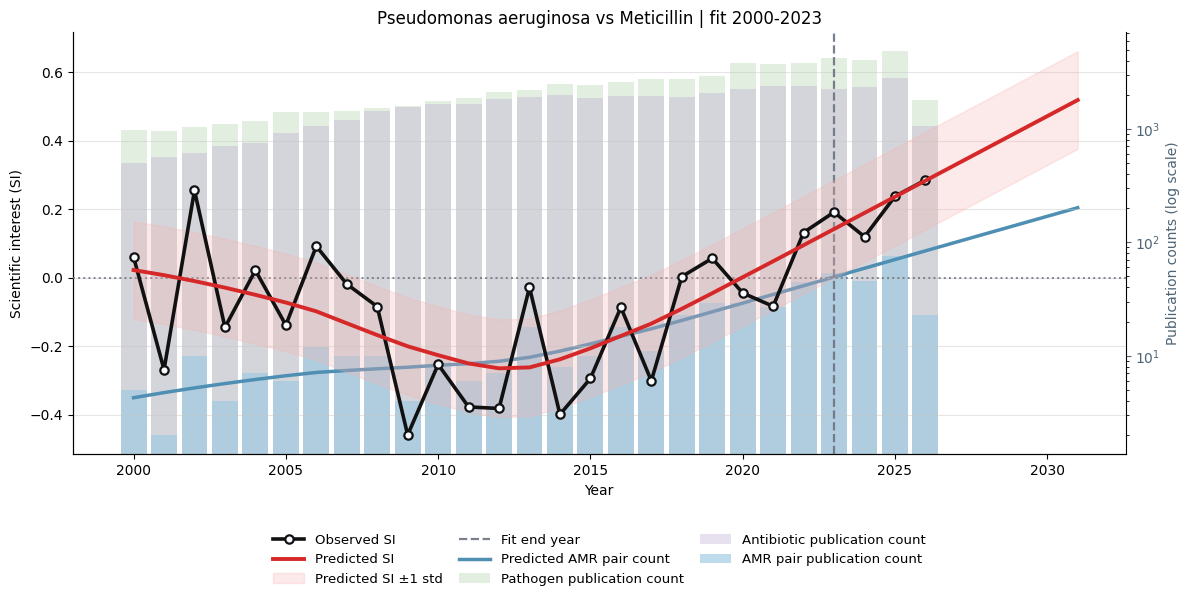

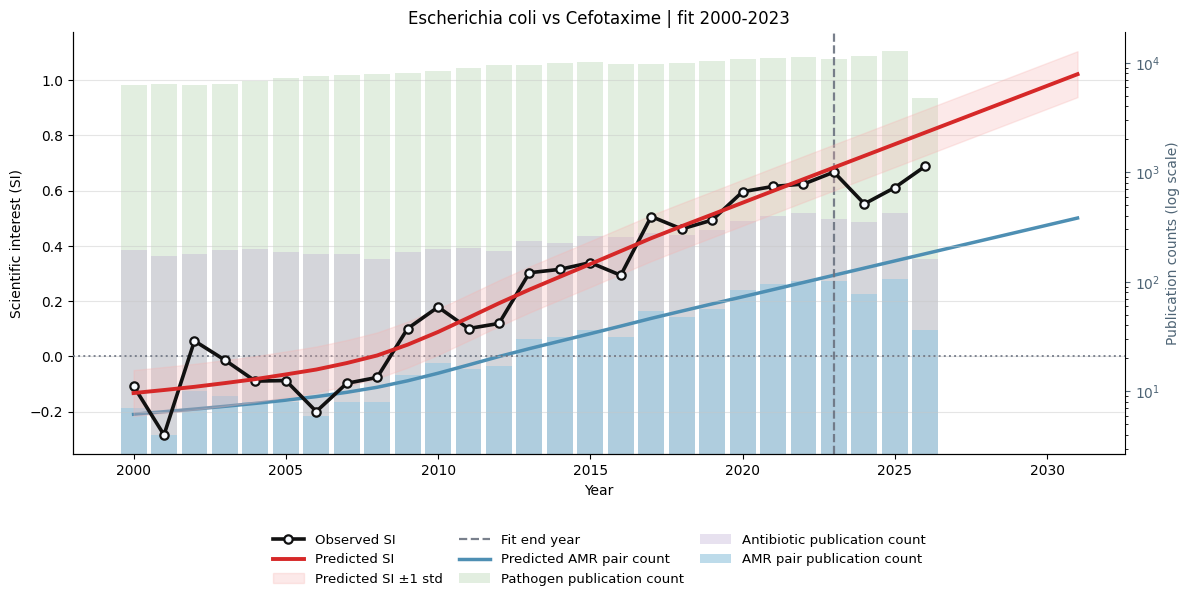

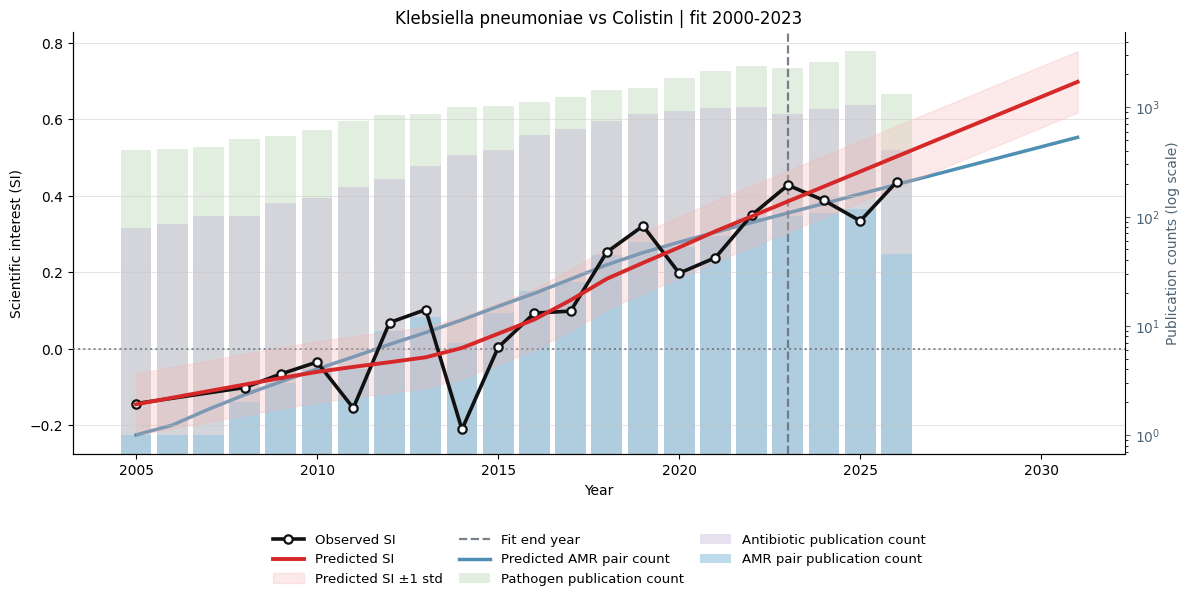

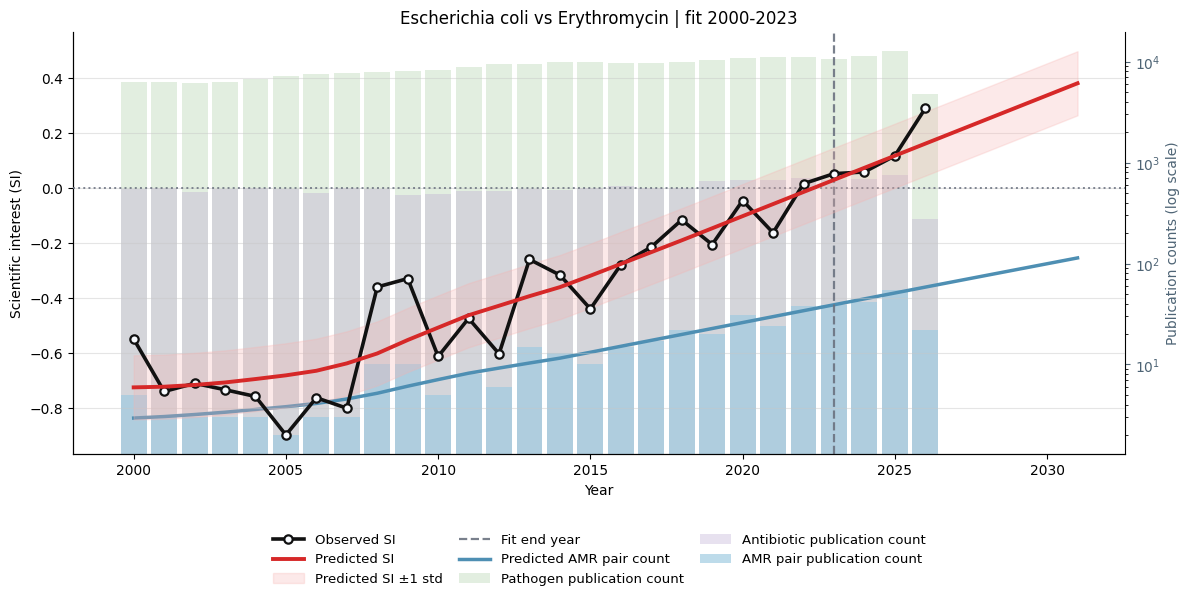

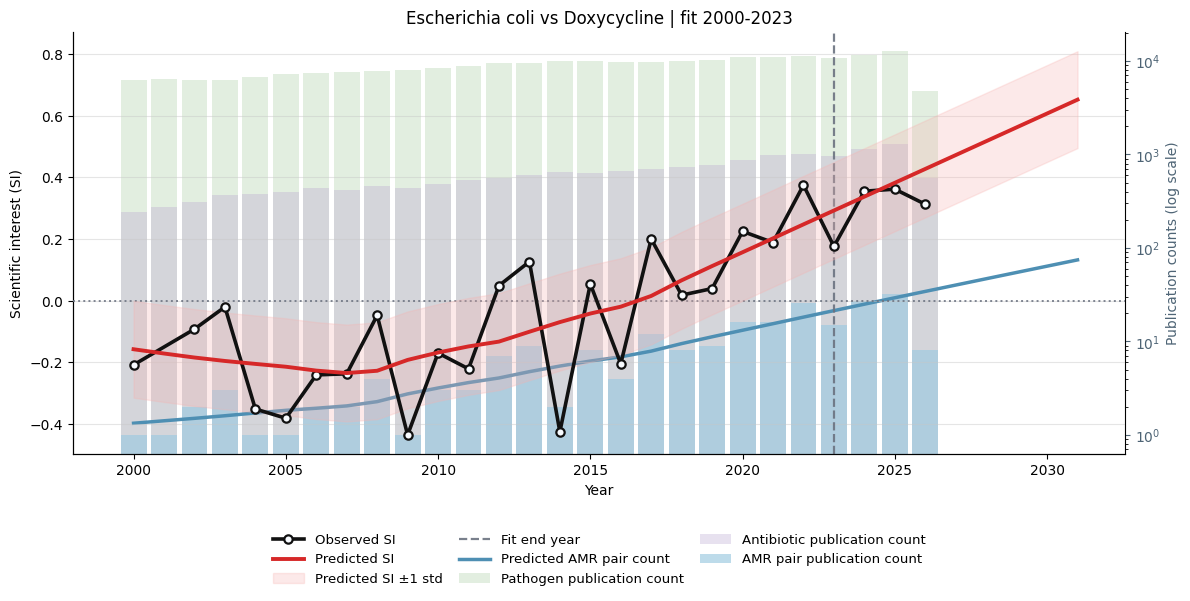

Saved 25 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [11]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)
